In [2]:
import matplotlib.pyplot as plt
import numpy as np

In [3]:
maps_file = "Maps_Mtot_Nbody_IllustrisTNG_LH_z=0.00.npy"
maps = np.load(maps_file, mmap_mode="r")
params_file = "params_LH_Nbody_IllustrisTNG.txt"
params = np.loadtxt(params_file, comments="#")

In [4]:
print(np.shape(maps))
# 15000 2d maps of size 256x256 pixels
# 15 projections of each simulation are stored consecutively
# want to split test and training by simulation so there aren't any maps of the same simulation in
# both training and test

print(np.shape(params))
# the params file has 1000 rows for each simulation,
# & 6 columns: Omega_m, sigma_8, A_SN1, A_AGN1, A_SN2, A_AGN2

(15000, 256, 256)
(1000, 6)


In [5]:
rng = np.random.default_rng(42)          # fixed seed so the split is reproducible
sims = rng.permutation(1000)
train_sims, val_sims, test_sims = sims[:800], sims[800:900], sims[900:]

def sim_to_map_indices(sim_ids, maps_per_sim=15):
    return (sim_ids[:, None] * maps_per_sim + np.arange(maps_per_sim)).ravel()

train_idx = sim_to_map_indices(train_sims)
val_idx   = sim_to_map_indices(val_sims)
test_idx  = sim_to_map_indices(test_sims)
labels = np.repeat(params[:, :2], 15, axis=0)   # per-map labels

In [6]:
print(len(train_idx), len(val_idx), len(test_idx))
# (maps[train_idx] would copy ~3 GB into RAM just to get its length, so use the index arrays)

12000 1500 1500


In [7]:
# make sure the 15 projections of each sim are not split among training, validation and test
sims_in = lambda idx: set(idx // 15)
assert sims_in(train_idx).isdisjoint(sims_in(val_idx))
assert sims_in(train_idx).isdisjoint(sims_in(test_idx))
assert sims_in(val_idx).isdisjoint(sims_in(test_idx))
assert len(np.unique(np.concatenate([train_idx, val_idx, test_idx]))) == len(maps)
print("split OK: every simulation is in exactly one of train / val / test")

split OK: every simulation is in exactly one of train / val / test


## The CNN

1. **Preprocess:** take log10 of each map and standardize it with training-set statistics. Rescale the labels (Omega_m, sigma_8) to [0, 1].
2. **Network:** 6 convolutional blocks, each halving the image (256 → 4 pixels), then global average pooling and a small fully connected head. The head outputs a **mean and an uncertainty** for each parameter.
3. **Loss:** Gaussian negative log-likelihood, so the network learns error bars along with its predictions.
4. **Augmentation:** random 90° rotations and flips, since cosmology has no preferred direction.
5. **Training:** AdamW with a one-cycle learning-rate schedule. The model with the best validation loss is saved, and the test set is used only once, at the end.

In [8]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

CHUNK = 250   # maps read from disk at a time, to keep memory use low

def log_chunks(m, idx):
    """Yield log10 of the maps m[idx] in chunks. The matter density spans several
    orders of magnitude, so the log is a much better input for the network than raw values."""
    for i in range(0, len(idx), CHUNK):
        yield np.log10(np.asarray(m[idx[i:i+CHUNK]], dtype=np.float32))

# Normalization statistics from TRAINING maps only (a random subset is plenty), so test data never leaks in
tot, tot2, n = 0.0, 0.0, 0
for c in log_chunks(maps, np.sort(rng.choice(train_idx, 1500, replace=False))):
    c = c.astype(np.float64)
    tot += c.sum(); tot2 += (c**2).sum(); n += c.size
LOG_MEAN = tot / n
LOG_STD = np.sqrt(tot2 / n - LOG_MEAN**2)
print(f"log10(map) mean {LOG_MEAN:.3f}, std {LOG_STD:.3f}")

def prepare(m, idx):
    """Standardized log maps as a float16 tensor of shape (N, 1, 256, 256).
    float16 halves the RAM (train set ~1.6 GB instead of 3.1 GB); batches are converted to float32 for training."""
    X = np.empty((len(idx), 1, 256, 256), dtype=np.float16)
    for i, c in zip(range(0, len(idx), CHUNK), log_chunks(m, idx)):
        assert np.isfinite(c).all(), "map has zero or negative pixels; log10 failed"
        X[i:i+len(c), 0] = (c - LOG_MEAN) / LOG_STD
    return torch.from_numpy(X)

# Labels: rescale Omega_m and sigma_8 to [0, 1] so both get equal weight in the loss
y_lo, y_hi = params[:, :2].min(0), params[:, :2].max(0)
y_span = y_hi - y_lo
norm_y   = lambda y: (y - y_lo) / y_span
denorm_y = lambda y: y * y_span + y_lo

X_train, X_val, X_test = prepare(maps, train_idx), prepare(maps, val_idx), prepare(maps, test_idx)
Y_train, Y_val, Y_test = [torch.tensor(norm_y(labels[i]), dtype=torch.float32)
                          for i in (train_idx, val_idx, test_idx)]
print(X_train.shape, Y_train.shape, X_val.shape, X_test.shape)

device: cpu
log10(map) mean 9.066, std 0.497
torch.Size([12000, 1, 256, 256]) torch.Size([12000, 2]) torch.Size([1500, 1, 256, 256]) torch.Size([1500, 1, 256, 256])


In [ ]:
# shrink the maps to 128x128 to make it faster

import torch.nn.functional as F
def downsample(X, bs=500):
    return torch.cat([F.avg_pool2d(X[i:i+bs].float(), 2).half() for i in range(0, len(X), bs)])
X_train, X_val, X_test = downsample(X_train), downsample(X_val), downsample(X_test)

In [10]:
def conv_block(c_in, c_out):
    """Two 3x3 convolutions, then a stride-2 convolution that halves the image size.
    Circular padding because the simulation box is periodic: the maps wrap around at the edges."""
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, padding_mode="circular", bias=False),
        nn.BatchNorm2d(c_out), nn.LeakyReLU(0.2),
        nn.Conv2d(c_out, c_out, 3, padding=1, padding_mode="circular", bias=False),
        nn.BatchNorm2d(c_out), nn.LeakyReLU(0.2),
        nn.Conv2d(c_out, c_out, 2, stride=2, bias=False),
        nn.BatchNorm2d(c_out), nn.LeakyReLU(0.2),
    )

class CosmoCNN(nn.Module):
    """256x256 map -> (mean, log variance) for (Omega_m, sigma_8)."""
    def __init__(self, width=8, dropout=0.3):
        # smaller width = faster, changed from 16 to 8
        super().__init__()
        w = width
        chans = [1, w, 2*w, 4*w, 8*w, 16*w, 16*w]      # image size 256 -> 128 -> 64 -> 32 -> 16 -> 8 -> 4
        self.features = nn.Sequential(*[conv_block(a, b) for a, b in zip(chans[:-1], chans[1:])])
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Dropout(dropout), nn.Linear(chans[-1], 128), nn.LeakyReLU(0.2),
            nn.Dropout(dropout), nn.Linear(128, 4),
        )

    def forward(self, x):
        out = self.head(self.features(x))
        return out[:, :2], out[:, 2:].clamp(-12, 4)    # mean, log variance

def gaussian_nll(mean, log_var, y):
    """Negative log-likelihood of y under N(mean, exp(log_var)). Training on this instead of MSE
    makes the network also learn an error bar for each prediction."""
    return (0.5 * log_var + 0.5 * (y - mean) ** 2 / log_var.exp()).mean()

def augment(x):
    """The universe has no preferred direction, so a rotated or mirrored map has the same
    Omega_m and sigma_8. Random rotations by 90 degrees and flips give 8x more distinct training maps."""
    x = torch.rot90(x, int(torch.randint(4, (1,))), dims=(2, 3))
    flip = torch.rand(x.shape[0], device=x.device) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)

# quick shape check
with torch.no_grad():
    m, lv = CosmoCNN()(torch.zeros(2, 1, 256, 256))
print(m.shape, lv.shape)

torch.Size([2, 2]) torch.Size([2, 2])


In [11]:
import math, time, os

EPOCHS = 10      # each epoch = one pass over the 12000 training maps
BATCH  = 64
LR     = 1e-3
CKPT   = "cosmo_cnn_best.pt"

torch.manual_seed(0)
model = CosmoCNN().to(device)
print(f"{sum(p.numel() for p in model.parameters()):,} trainable parameters")

torch.set_num_threads(os.cpu_count())

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
steps_per_epoch = math.ceil(len(X_train) / BATCH)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, total_steps=EPOCHS * steps_per_epoch)

@torch.no_grad()
def predict(X, bs=256):
    """Return (mean, sigma) in normalized label units for every map in X."""
    model.eval()
    means, sigmas = [], []
    for i in range(0, len(X), bs):
        m, log_var = model(X[i:i+bs].to(device).float())
        means.append(m.cpu()); sigmas.append((0.5 * log_var).exp().cpu())
    return torch.cat(means).numpy(), torch.cat(sigmas).numpy()

def nll_numpy(mean, sigma, y):
    return np.mean(np.log(sigma) + 0.5 * ((y - mean) / sigma) ** 2)

history = {"train": [], "val": []}
best_val = np.inf
for epoch in range(EPOCHS):
    model.train()
    t0, running = time.time(), 0.0
    order = torch.randperm(len(X_train))
    for i in range(0, len(X_train), BATCH):
        b = order[i:i+BATCH]
        x = augment(X_train[b].to(device, non_blocking=True).float())
        y = Y_train[b].to(device)
        mean, log_var = model(x)
        loss = gaussian_nll(mean, log_var, y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step(); sched.step()
        running += loss.item() * len(b)

    vm, vs = predict(X_val)
    val_loss = nll_numpy(vm, vs, Y_val.numpy())
    val_rmse = np.sqrt(np.mean((denorm_y(vm) - denorm_y(Y_val.numpy())) ** 2, axis=0))
    history["train"].append(running / len(X_train)); history["val"].append(val_loss)
    if val_loss < best_val:
        best_val = val_loss
        torch.save(model.state_dict(), CKPT)
    print(f"epoch {epoch+1:2d} | train {history['train'][-1]:.3f} | val {val_loss:.3f} "
          f"| val RMSE  Om {val_rmse[0]:.4f}  s8 {val_rmse[1]:.4f} | {time.time()-t0:.0f}s"
          + ("  *saved" if val_loss == best_val else ""))

761,436 trainable parameters
epoch  1 | train -0.237 | val -0.636 | val RMSE  Om 0.0913  s8 0.1368 | 175s  *saved
epoch  2 | train -1.038 | val -0.884 | val RMSE  Om 0.0918  s8 0.0969 | 125s  *saved
epoch  3 | train -1.322 | val -1.192 | val RMSE  Om 0.0910  s8 0.0483 | 203s  *saved
epoch  4 | train -1.465 | val -1.139 | val RMSE  Om 0.0782  s8 0.0678 | 196s
epoch  5 | train -1.536 | val -1.793 | val RMSE  Om 0.0368  s8 0.0334 | 169s  *saved
epoch  6 | train -1.632 | val -1.833 | val RMSE  Om 0.0389  s8 0.0387 | 131s  *saved
epoch  7 | train -1.713 | val -1.873 | val RMSE  Om 0.0355  s8 0.0357 | 199s  *saved
epoch  8 | train -1.780 | val -1.969 | val RMSE  Om 0.0324  s8 0.0375 | 135s  *saved
epoch  9 | train -1.814 | val -2.051 | val RMSE  Om 0.0285  s8 0.0298 | 136s  *saved
epoch 10 | train -1.824 | val -2.046 | val RMSE  Om 0.0302  s8 0.0314 | 101s


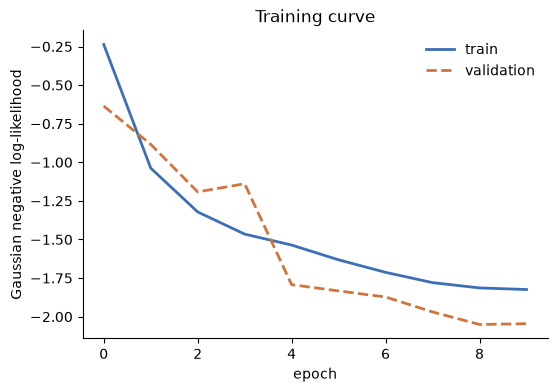

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(history["train"], color="#3b6fb6", lw=2, label="train")
ax.plot(history["val"], color="#d0743c", lw=2, ls="--", label="validation")
ax.set_xlabel("epoch")
ax.set_ylabel("Gaussian negative log-likelihood")
ax.set_title("Training curve")
ax.legend(frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

In [13]:
# Evaluate the best model (lowest validation loss) on the held-out TEST simulations
model.load_state_dict(torch.load(CKPT, map_location=device))
pred_mean, pred_sig = predict(X_test)
pred_mean = denorm_y(pred_mean)          # back to physical units
pred_sig  = pred_sig * y_span
true      = labels[test_idx]

# Each sim has 15 maps of the same universe; average them to get one estimate per simulation
sim_mean = pred_mean.reshape(-1, 15, 2).mean(1)
sim_sig  = pred_sig.reshape(-1, 15, 2).mean(1)    # typical single-map uncertainty
sim_true = true.reshape(-1, 15, 2)[:, 0]

names = ["Omega_m", "sigma_8"]
for j, name in enumerate(names):
    err = pred_mean[:, j] - true[:, j]
    rmse = np.sqrt(np.mean(err**2))
    r2 = 1 - np.sum(err**2) / np.sum((true[:, j] - true[:, j].mean())**2)
    rel = np.mean(np.abs(err) / true[:, j])
    within = np.mean(np.abs(err) < pred_sig[:, j])     # should be ~0.68 if sigma is calibrated
    rmse_sim = np.sqrt(np.mean((sim_mean[:, j] - sim_true[:, j])**2))
    print(f"{name}: RMSE {rmse:.4f} | mean rel. error {100*rel:.1f}% | R^2 {r2:.3f} "
          f"| truth within 1 sigma: {100*within:.0f}% | RMSE of 15-map average {rmse_sim:.4f}")

Omega_m: RMSE 0.0296 | mean rel. error 7.8% | R^2 0.935 | truth within 1 sigma: 88% | RMSE of 15-map average 0.0188
sigma_8: RMSE 0.0302 | mean rel. error 2.8% | R^2 0.936 | truth within 1 sigma: 88% | RMSE of 15-map average 0.0189


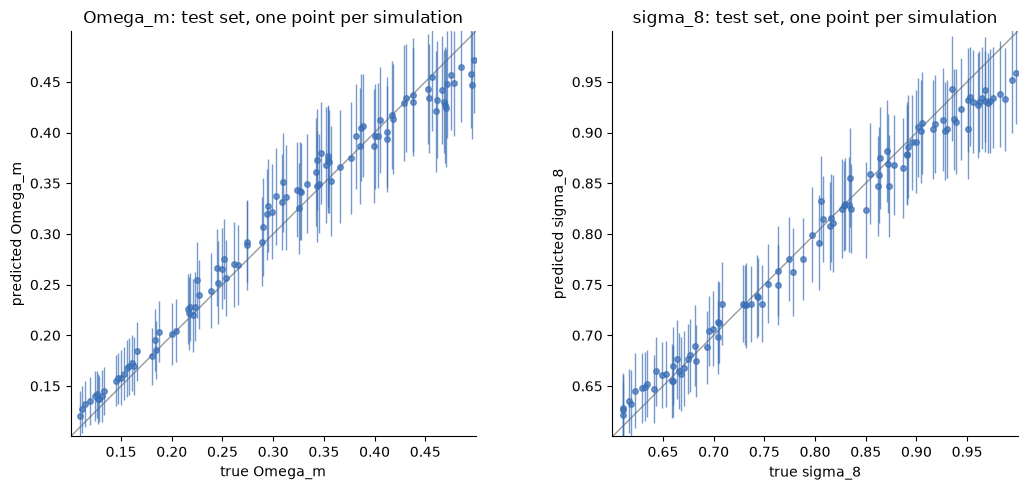

In [14]:
# Predicted vs. true, one point per simulation (average of its 15 maps), with the predicted 1-sigma error
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for j, (ax, name) in enumerate(zip(axes, names)):
    lo, hi = y_lo[j], y_hi[j]
    ax.plot([lo, hi], [lo, hi], color="0.6", lw=1, zorder=0)          # perfect prediction
    ax.errorbar(sim_true[:, j], sim_mean[:, j], yerr=sim_sig[:, j], fmt="o", ms=4,
                color="#3b6fb6", ecolor="#3b6fb6", elinewidth=1, alpha=0.7, capsize=0)
    ax.set_xlabel(f"true {name}")
    ax.set_ylabel(f"predicted {name}")
    ax.set_title(f"{name}: test set, one point per simulation")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

In [15]:
# Extra check: the CV set. All 27 CV simulations share ONE cosmology (Omega_m=0.3, sigma_8=0.8)
# and differ only in their random initial conditions. The scatter of the predictions shows how much
# cosmic variance alone moves the estimate, and the mean shows whether the network is biased.
maps_cv   = np.load("Maps_Mtot_Nbody_IllustrisTNG_CV_z=0.00.npy", mmap_mode="r")
params_cv = np.loadtxt("params_CV_Nbody_IllustrisTNG.txt", comments="#")
X_cv = prepare(maps_cv, np.arange(len(maps_cv)))
cv_mean, cv_sig = predict(X_cv)
cv_mean, cv_sig = denorm_y(cv_mean), cv_sig * y_span

for j, name in enumerate(names):
    print(f"{name}: truth {params_cv[0, j]:.3f} | mean prediction {cv_mean[:, j].mean():.4f} "
          f"| scatter between maps {cv_mean[:, j].std():.4f} | mean predicted sigma {cv_sig[:, j].mean():.4f}")

Omega_m: truth 0.300 | mean prediction 0.4404 | scatter between maps 0.0316 | mean predicted sigma 0.0557
sigma_8: truth 0.800 | mean prediction 0.6113 | scatter between maps 0.0117 | mean predicted sigma 0.0311
